# Representation Study: Do Pretrained Chemical-Language-Model Embeddings Help?

**Goal.** Test whether representations learned by a pretrained **chemical language model (CLM)** predict normal boiling points better than conventional molecular features, especially for chemistry unlike the training data and when few labels are available, and whether their uncertainty can be trusted. Better accuracy is a hypothesis to test, not an assumed outcome: if the physically motivated descriptors still win, that is a valid finding.

**Data.** The 1,250 literature boiling points that pass the label audit (`data/label_audit.csv`). That is the 1,251 measured labels of `Label_Audit.ipynb` minus one stereoisomer conflict found here (section 1).

**Representations compared**, all computed from the same cleaned SMILES (simplified molecular-input line-entry system) string, with stereochemistry and isotope labels removed:
- **Curated descriptors:** the 43 RDKit descriptors of `Boiling_Point_RDKit.ipynb`, with log-transformed size and shape terms.
- **Morgan counts:** circular fingerprints of radius 2 hashed into 2,048 bins, counting each atom environment.
- **MoLFormer embeddings:** MoLFormer-XL (IBM, Apache-2.0), a CLM pretrained by masked-token prediction on SMILES from 10% of ZINC15 and 10% of PubChem (per its model card). It is used two ways: **frozen**, where each molecule is represented by the average of one layer's token vectors and only a regressor on top is trained, and **fine-tuned**, where all of its weights are trained on boiling points (section 7).

**Three evaluation regimes**, each a different question:
1. **Familiar chemistry:** 5-fold cross-validation repeated 3 times, stratified by chemical family and grouped by structure, so stereoisomers never sit on both sides of a split.
2. **Unseen functional group:** train on three of the four families and predict the fourth.
3. **Unseen elements and rings:** train on all 1,250 acyclic C/H/N/O compounds and predict 211 compounds from the NIST (National Institute of Standards and Technology) WebBook, many with halogens or rings.

**Regressors:** Ridge and XGBoost, tuned in an inner cross-validation inside each training set. The **best pipeline** for a representation is whichever of the two has the lower inner-cross-validation error.

**Confirmatory tests (fixed before any result).** Each compares best pipelines by **mean absolute error (MAE)**, as MAE(MoLFormer) − MAE(curated descriptors), so a positive value means MoLFormer is worse. C1 covers familiar chemistry, C2 the family holdout (averaged with equal weight per family), C3 the NIST set (equal weight per subgroup), and C4 familiar chemistry with only 100 training molecules. C5 compares fine-tuned with frozen MoLFormer, as MAE(fine-tuned) − MAE(frozen). A difference counts as a finding only if it survives Holm's correction across all five and is at least **1.0 K**. That minimum was set from the label noise floor (section 1) before any model was run.

All results here are precomputed. `scripts/build_representation_splits.py` fixes the splits, `scripts/build_representations.py` caches the embeddings, `scripts/run_representation_study.py --stage A|B` runs the frozen comparison, `scripts/run_finetuning.py` the fine-tuning, `scripts/run_learning_curves.py` the learning curves, `scripts/run_uncertainty.py` the prediction intervals, and `scripts/confirmatory.py` the final tests.

**Contents**
1. Data, splits and label noise: what is evaluated, and how noisy the labels are
2. Morgan bits or counts: why the conventional baseline uses counts
3. What the frozen embeddings encode: label-free probes of spelling and chain length
4. Familiar chemistry: cross-validated error of every representation and regressor
5. Unseen functional groups: leave-one-family-out
6. Unseen elements and rings: the external NIST set
7. Fine-tuning MoLFormer: does training the whole encoder help?
8. Learning curves: 100 to ~1,000 training molecules
9. Confirmatory comparisons C1–C5, and descriptive Morgan contrasts
10. Prediction intervals and uncertainty: are the error bars honest?
11. Key findings

In [1]:
from boiling_point import representations as rep  # boiling_point first: loads xgboost before torch

import warnings
warnings.filterwarnings("ignore")

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", None)   # show every column and full text in tables
pd.set_option("display.max_colwidth", None)
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

R, F, IMG = "results/representation_study", "results/representation_study/frozen", "results/images"
FT, LC, U = f"{R}/finetune", f"{R}/learning_curve", f"{R}/uncertainty"
splits = pd.read_csv(f"{R}/splits.csv")
nist = pd.read_csv(f"{R}/nist_external.csv")
noise = pd.read_csv("data/nist_noise_floor_lookups.csv")
preds = pd.concat([pd.read_csv(f"{F}/ridge_predictions.csv"), pd.read_csv(f"{F}/xgboost_predictions.csv")],
                  ignore_index=True)
best = pd.read_csv(f"{F}/best_predictions.csv")
refs = pd.read_csv(f"{F}/references.csv")
for t in (preds, best, refs):
    t["abs_err"] = (t["y_pred"] - t["y_true"]).abs()
subgroup = dict(zip("nist:" + nist.index.astype(str), nist["subgroup"]))

REPS = ["curated", "molformer", "morgan"]
NAMES = {"curated": "Curated descriptors", "molformer": "MoLFormer (frozen)", "morgan": "Morgan counts"}
COLORS = {"curated": "#2a78d6", "molformer": "#eb6834", "morgan": "#1baf7a"}
GREY = "#a3a29c"
REG = {"ridge": "Ridge", "xgboost": "XGBoost"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.5,
                     "axes.edgecolor": "#8a8984", "font.size": 9})

## 1. Data, splits and label noise

The splits were generated once and committed before any model was compared. Molecules are grouped by the first block of their InChIKey, which ignores stereochemistry and isotopes. That keeps stereoisomers, and methane with deuterated methane, together in every split.

The label audit gained one check for this study: labels of the same structure that differ by more than 30 K. Enantiomers boil at the same temperature, so (R,R)-2,3-butanediol at 350.5 K, against 453.65 K for its enantiomer, was excluded. A cis/trans pair was only flagged, because diastereomers can genuinely differ. The table counts what each regime evaluates:

In [2]:
held = splits["holdout_family"].fillna("")
kept = nist[~nist["exclude"]]
rows = [("literature compounds (measured labels)", len(splits)),
        ("structure groups (InChIKey connectivity)", splits["structure_group"].nunique()),
        ("familiar regime: test molecules per fold", int(splits.groupby("fold_r0").size().mean()))]
rows += [(f"holdout regime: held-out {f}", int((held == f).sum())) for f in sorted(set(held) - {""})]
rows += [("holdout regime: left out (family 'other')", int((held == "").sum())),
         ("NIST rows / kept", f"{len(nist)} / {len(kept)}")]
rows += [(f"NIST kept: {g}", int(n)) for g, n in kept["subgroup"].value_counts().items()]
rows += [("NIST kept: single NIST measurement", int(kept["single_measurement"].sum()))]
pd.DataFrame(rows, columns=["item", "count"]).set_index("item")

,count
item,
literature compounds (measured labels),1250
structure groups (InChIKey connectivity),1181
familiar regime: test molecules per fold,250
holdout regime: held-out alcohol/phenol,351
holdout regime: held-out alkane,388
holdout regime: held-out alkene/alkyne,366
holdout regime: held-out amine,142
holdout regime: left out (family 'other'),3
NIST rows / kept,213 / 211


**How noisy are the labels?** To set a scale for "meaningful", 100 measured compounds were sampled at random, stratified by family, and looked up on NIST by InChI, keeping every NIST measurement. Two numbers matter: how far our label sits from NIST's median, and how far NIST's own measurements spread for one compound. The spread uses a robust standard deviation (SD): 1.4826 × the median absolute deviation, a scale that matches the SD for normally distributed data.

In [3]:
found = noise[noise["status"] == "found"].copy()
values = found["nist_values"].astype(str).map(lambda s: np.array([float(v) for v in s.split(";")]))
gap = (found["label"] - found["nist_median"]).abs()
robust_sd = values[values.map(len) >= 3].map(lambda v: 1.4826 * np.median(np.abs(v - np.median(v))))
pd.DataFrame({
    "value": [len(noise), int((noise["status"] == "found").sum()), round(gap.mean(), 2), round(gap.median(), 2),
              round(gap.quantile(0.9), 2), round(gap.max(), 2), round((gap <= 1).mean(), 2),
              len(robust_sd), round(robust_sd.median(), 2)]},
    index=["compounds sampled", "with a NIST boiling point", "|label − NIST median|: mean (K)",
           "|label − NIST median|: median (K)", "|label − NIST median|: 90th percentile (K)",
           "|label − NIST median|: max (K)", "share within 1 K", "compounds with ≥ 3 NIST values",
           "NIST robust SD per compound: median (K)"])

,value
compounds sampled,100.00
with a NIST boiling point,43.00
|label − NIST median|: mean (K),0.55
|label − NIST median|: median (K),0.09
|label − NIST median|: 90th percentile (K),1.20
|label − NIST median|: max (K),6.00
share within 1 K,0.79
compounds with ≥ 3 NIST values,22.00
NIST robust SD per compound: median (K),0.30


- **Our labels agree closely with NIST.** For the 43 of 100 sampled compounds that NIST has, the label is a mean 0.55 K from NIST's median (median 0.09 K), 79% are within 1 K, and the worst gap is 6.00 K.
- NIST's own measurements of one compound spread by a median robust SD of 0.30 K, across the 22 compounds with at least 3 values.
- So label noise is about half a kelvin. The 1.0 K minimum meaningful difference used in the confirmatory tests is about twice the mean gap of 0.55 K.
- NIST covers well-studied compounds, so these numbers may understate the noise in the rest of the dataset.

## 2. Morgan bits or counts

A Morgan fingerprint records which atom environments, up to a radius, occur in a molecule. The binary version only marks presence, so it can't see how *many* times an environment occurs. In a long chain every interior CH₂ looks the same, so the bit vector stops changing once the chain is long enough. The table counts groups of molecules whose fingerprints are identical, and the boiling-point spread inside them:

In [4]:
smiles = splits["isosmiles"].map(rep.model_smiles)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
mols = [Chem.MolFromSmiles(s) for s in smiles]
fingerprints = {"bits": [tuple(gen.GetFingerprint(m).GetOnBits()) for m in mols],
                "counts": [tuple(sorted(gen.GetCountFingerprint(m).GetNonzeroElements().items())) for m in mols]}
rows = []
for name, fp in fingerprints.items():
    g = splits.assign(fp=fp).groupby("fp")["boiling_point_kelvin"]
    size, spread = g.size(), g.max() - g.min()
    rows.append({"fingerprint": name, "groups of identical vectors": int((size > 1).sum()),
                 "molecules in them": int(size[size > 1].sum()), "groups spanning > 20 K": int((spread > 20).sum()),
                 "largest spread (K)": round(spread.max(), 1)})
alkanes = splits[smiles.isin(["C" * n for n in (8, 10, 12)])][["cmpdname", "boiling_point_kelvin"]]
display(pd.DataFrame(rows).set_index("fingerprint"))
alkanes.assign(same_bits=[fingerprints["bits"][i] == fingerprints["bits"][alkanes.index[0]] for i in alkanes.index])

,groups of identical vectors,molecules in them,groups spanning > 20 K,largest spread (K)
fingerprint,,,,
bits,84,366,38,449.6
counts,57,128,2,104.0


,cmpdname,boiling_point_kelvin,same_bits
4,Octane,398.77,True
111,Dodecane,489.45,True
325,Decane,447.25,True


- **Bits leave many molecules indistinguishable.** With bits, 84 groups (366 molecules) share an identical fingerprint; 38 of these groups span more than 20 K, one of them 449.6 K. With counts, 57 groups (128 molecules) share one, and only 2 span more than 20 K.
- Octane, decane and dodecane have identical bit vectors, although their boiling points run from 398.77 to 489.45 K. Bits can't record chain length.
- So the conventional baseline uses counts (radius 2, 2,048 bins). A choice known in advance to lose information would make it a straw man.

## 3. What the frozen embeddings encode

Two probes use no boiling points, so they can't bias the comparison. MoLFormer has 14 candidate "layers": layer 0 is the average of the raw token embeddings (no context), layers 1–12 are the encoder layers, and 13 is the model's own pooled output (layer 12 after a final normalisation).

**Spelling.** One molecule has many valid SMILES strings: ethanol is `CCO`, `OCC` or `C(O)C`. Each molecule was written 10 more ways, and every spelling's embedding was compared with the canonical embeddings of all 1,181 distinct molecules. *Retrieval share* is how often a spelling's nearest canonical embedding is its own molecule's. *Distance ratio* is how far the spelling moved the embedding, divided by the distance to the nearest other molecule; above 1, the spelling moved it further than that gap.

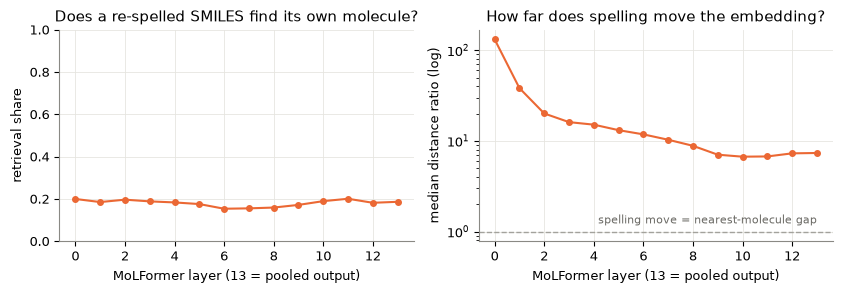

layer,hidden_0,hidden_1,hidden_2,hidden_3,hidden_4,hidden_5,hidden_6,hidden_7,hidden_8,hidden_9,hidden_10,hidden_11,hidden_12,pooler
retrieval_share,0.200,0.185,0.196,0.188,0.183,0.176,0.154,0.155,0.159,0.172,0.190,0.201,0.182,0.186
median_distance_ratio,132.133,38.273,20.110,16.134,15.128,13.156,11.824,10.316,8.842,7.055,6.707,6.747,7.299,7.366


In [5]:
inv = pd.read_csv(f"{R}/probes_invariance.csv")
inv["layer_no"] = range(len(inv))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3))
axes[0].plot(inv["layer_no"], inv["retrieval_share"], marker="o", ms=4, color=COLORS["molformer"])
axes[0].set(ylim=(0, 1), xlabel="MoLFormer layer (13 = pooled output)", ylabel="retrieval share",
            title="Does a re-spelled SMILES find its own molecule?")
axes[1].semilogy(inv["layer_no"], inv["median_distance_ratio"], marker="o", ms=4, color=COLORS["molformer"])
axes[1].axhline(1, color=GREY, ls="--", lw=1)
axes[1].text(13, 1.15, "spelling move = nearest-molecule gap", ha="right", va="bottom", color="#6b6a65", fontsize=8)
axes[1].set(xlabel="MoLFormer layer (13 = pooled output)", ylabel="median distance ratio (log)",
            title="How far does spelling move the embedding?")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_spelling_probe.png", dpi=150)
plt.show()
inv[["layer", "retrieval_share", "median_distance_ratio"]].round(3).set_index("layer").T

- **Re-spelling usually loses the molecule.** The retrieval share stays between 0.154 and 0.201 in every layer, so a re-spelled SMILES usually lands nearer another molecule's canonical embedding than its own.
- In layers 1–13, re-spelling moves the embedding 6.7 to 38 times further than the gap to the nearest other molecule (hidden_10: 6.707; hidden_1: 38.273). Layer 0, a context-free token average, reaches 132.
- **The frozen embeddings depend strongly on how a molecule is written.** MoLFormer was pretrained on canonical SMILES only, so this study gives it canonical SMILES throughout, a choice fixed in advance.

**Chain length.** Within the n-alkanes (C1–C44), 1-alcohols and 1-amines, do consecutive homologues stay distinguishable beyond eight carbons, where binary Morgan bits stop changing? The table shows the median distance between consecutive homologues up to and beyond C8, and the share of steps beyond C8 that leave the representation unchanged. MoLFormer is shown at layer 1, the layer the familiar-chemistry Ridge models chose (section 4), and at its pooled output.

In [6]:
chain = pd.read_csv(f"{R}/probes_chain_length.csv")
show = chain[chain["representation"].isin(["morgan_bits", "morgan_counts", "hidden_1", "pooler"])]
show.set_index(["series", "representation"])[["n", "chain_lengths", "median_step_distance_upto_C8",
                                              "median_step_distance_beyond_C8",
                                              "share_steps_beyond_C8_unchanged"]].round(4)

n chain_lengths  median_step_distance_upto_C8  \
series    representation                                                   
n-alkane  hidden_1        41        C1-C44                        0.0071   
          pooler          41        C1-C44                        0.0913   
          morgan_bits     41        C1-C44                        0.3239   
          morgan_counts   41        C1-C44                        0.1598   
1-alcohol hidden_1        19        C1-C24                        0.0058   
          pooler          19        C1-C24                        0.0525   
          morgan_bits     19        C1-C24                        0.1296   
          morgan_counts   19        C1-C24                        0.0785   
1-amine   hidden_1        17        C1-C18                        0.0093   
          pooler          17        C1-C18                        0.1858   
          morgan_bits     17        C1-C18                        0.2088   
          morgan_counts   17        C1-C18                        0.1404   

                          median_step_distance_beyond_C8  \
series    representation                                   
n-alkane  hidden_1                                0.0006   
          pooler                                  0.0075   
          morgan_bits                             0.0000   
          morgan_counts                           0.0000   
1-alcohol hidden_1                                0.0014   
          pooler                                  0.0318   
          morgan_bits                            -0.0000   
          morgan_counts                           0.0002   
1-amine   hidden_1                                0.0009   
          pooler                                  0.0144   
          morgan_bits                            -0.0000   
          morgan_counts                           0.0003   

                          share_steps_beyond_C8_unchanged  
series    representation                                   
n-alkane  hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0  
1-alcohol hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0  
1-amine   hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0

- **Binary Morgan bits never change beyond C8** (share unchanged 1.0 in all three series). Morgan counts and both MoLFormer layers change at every step (share 0.0).
- **MoLFormer separates long chains, but compressed.** For n-alkanes at the pooled output, the median step falls from 0.0913 up to C8 to 0.0075 beyond it; at layer 1, from 0.0071 to 0.0006.
- Morgan counts also change at every step, but by tiny cosine distances beyond C8 (≤ 0.0003 in the table): one more CH₂ barely changes a vector dominated by the CH₂ count.

## 4. Familiar chemistry

Every representation was fitted with both regressors on the same 15 folds and the same inner folds. For MoLFormer, Ridge also chose the layer in the inner cross-validation, and XGBoost reused that layer. Each point below is one fold's test MAE. The dashed grey line is the feature study's ensemble (curated descriptors plus a family input, averaging Ridge, XGBoost and a neural network) on the same folds, for reference.

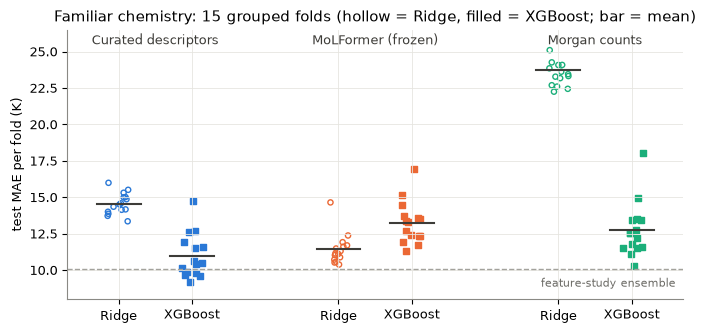

mean           std         best pipeline (folds)
regressor            ridge xgboost ridge xgboost                      
representation                                                        
Curated descriptors  14.56   11.00  0.72    1.51       {'xgboost': 15}
MoLFormer (frozen)   11.43   13.25  1.05    1.46         {'ridge': 15}
Morgan counts        23.71   12.75  1.29    1.86       {'xgboost': 15}

,mean,std
reference,,
"curated (log) + family ensemble (feature study, ungrouped inner CV)",10.08,1.06
molecular weight (Ridge),26.13,1.41
training mean,61.02,4.44


In [7]:
fam = preds[preds["regime"] == "familiar"]
fold_mae = fam.groupby(["representation", "regressor", "task"])["abs_err"].mean().reset_index()
ref_fold = refs[refs["regime"] == "familiar"].groupby(["reference", "task"])["abs_err"].mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
rng = np.random.default_rng(0)
for i, r in enumerate(REPS):
    for j, (reg, marker) in enumerate([("ridge", "o"), ("xgboost", "s")]):
        v = fold_mae[(fold_mae["representation"] == r) & (fold_mae["regressor"] == reg)]["abs_err"]
        x = i * 3 + j
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(v)), v, s=14, marker=marker, color=COLORS[r],
                   facecolors="none" if reg == "ridge" else COLORS[r], linewidths=1)
        ax.plot([x - 0.3, x + 0.3], [v.mean()] * 2, color="#3d3c38", lw=1.5)
ensemble = ref_fold.xs("curated (log) + family ensemble (feature study, ungrouped inner CV)").mean()
ax.axhline(ensemble, color=GREY, ls="--", lw=1)
ax.text(7.6, ensemble - 0.6, "feature-study ensemble", color="#6b6a65", fontsize=8, ha="right", va="top")
ax.set_xticks([0, 1, 3, 4, 6, 7], ["Ridge", "XGBoost"] * 3)
for i, r in enumerate(REPS):
    ax.text(i * 3 + 0.5, 25.5, NAMES[r], ha="center", color="#3d3c38", fontsize=9)
ax.set(ylabel="test MAE per fold (K)", ylim=(8, 26.5), xlim=(-0.7, 7.7),
       title="Familiar chemistry: 15 grouped folds (hollow = Ridge, filled = XGBoost; bar = mean)")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_familiar_folds.png", dpi=150)
plt.show()

table = fold_mae.groupby(["representation", "regressor"])["abs_err"].agg(["mean", "std"]).round(2).unstack()
chosen_reg = pd.read_csv(f"{F}/best_selection.csv").query("regime == 'familiar'")
table["best pipeline (folds)"] = chosen_reg.groupby("representation")["regressor"].agg(lambda s: s.value_counts().to_dict())
display(table.rename(index=NAMES))
ref_fold.groupby("reference").agg(["mean", "std"]).round(2)

- **XGBoost helps the conventional features but not the embeddings.** It beats Ridge for the curated descriptors (14.56 → 11.00 K) and Morgan counts (23.71 → 12.75 K), but not for MoLFormer (11.43 → 13.25 K). The inner cross-validation picked these same regressors in all 15 folds.
- **The best pipelines are close:** curated descriptors 11.00 ± 1.51 K, MoLFormer 11.43 ± 1.05 K, Morgan counts 12.75 ± 1.86 K. The gap between the first two (0.43 K) is well inside one fold SD.
- None beats the feature study's ensemble, at 10.08 ± 1.06 K. Molecular weight alone scores 26.13 K and the training mean 61.02 K.

**Which MoLFormer layer?** Ridge was fitted on every layer, each with its own penalty chosen in the inner cross-validation. The figure shows each layer's test MAE, averaged over the 15 folds; it is a diagnostic only, because the results above use the layer chosen in the inner cross-validation.

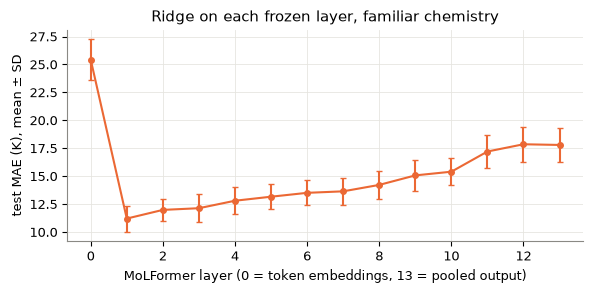

layer chosen in the inner CV, per fold: {1: 13, 2: 2}


layer,0,1,2,3,4,5,6,7,8,9,10,11,12,13
mean,25.43,11.21,11.99,12.14,12.81,13.17,13.51,13.65,14.22,15.08,15.41,17.21,17.86,17.80
std,1.82,1.17,1.01,1.26,1.19,1.13,1.12,1.21,1.28,1.36,1.19,1.45,1.56,1.54


In [8]:
probe = pd.read_csv(f"{F}/layer_probe.csv")
by_layer = probe.groupby("layer")["test_mae"].agg(["mean", "std"])
chosen = pd.read_csv(f"{F}/ridge_selection.csv").query("representation == 'molformer' and regime == 'familiar'")
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(by_layer.index, by_layer["mean"], yerr=by_layer["std"], marker="o", ms=4, capsize=2,
            color=COLORS["molformer"], lw=1.5)
ax.set(xlabel="MoLFormer layer (0 = token embeddings, 13 = pooled output)", ylabel="test MAE (K), mean ± SD",
       title="Ridge on each frozen layer, familiar chemistry")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_layer_probe.png", dpi=150)
plt.show()
print("layer chosen in the inner CV, per fold:", chosen["layer"].astype(int).value_counts().sort_index().to_dict())
by_layer.round(2).T

- Test MAE is lowest at layer 1 (11.21 ± 1.17 K). It rises steadily to 17.86 ± 1.56 K at layer 12 and 17.80 ± 1.54 K for the pooled output. Layer 0, the context-free token average, is worst at 25.43 ± 1.82 K.
- **The inner cross-validation agreed:** it chose layer 1 in 13 folds and layer 2 in 2, without seeing any test data.
- One pass of context removes most of the error (25.43 → 11.21 K). Deeper layers, trained to predict masked tokens, are progressively less useful for boiling point.

## 5. Unseen functional groups

Each family is predicted by models trained on the other three, with hyperparameters chosen by leave-one-family-out inside the training families, so tuning rewards extrapolation. The bars show each representation's best pipeline; the grey tick is a Ridge model on molecular weight alone.

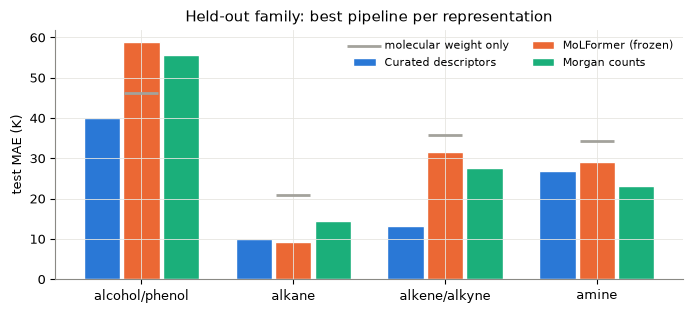

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
task,,,
alcohol/phenol,40.0,59.0,55.8
alkane,10.0,9.2,14.4
alkene/alkyne,13.3,31.5,27.7
amine,26.8,29.0,23.2
mean over families,22.5,32.2,30.3


best-pipeline regressor: {'curated': 'xgboost', 'molformer': 'ridge', 'morgan': 'xgboost'}


In [9]:
hold = best[best["regime"] == "holdout"].groupby(["task", "representation"])["abs_err"].mean().unstack()[REPS]
mw = refs[(refs["regime"] == "holdout") & (refs["reference"] == "molecular weight (Ridge)")].groupby("task")["abs_err"].mean()
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(hold))
for k, r in enumerate(REPS):
    ax.bar(x + (k - 1) * 0.26, hold[r], width=0.24, color=COLORS[r], label=NAMES[r], edgecolor="white", linewidth=1)
ax.scatter(x, mw.loc[hold.index], marker="_", s=600, color=GREY, linewidths=2, label="molecular weight only", zorder=3)
ax.set_xticks(x, hold.index)
ax.set(ylabel="test MAE (K)", title="Held-out family: best pipeline per representation")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_family_holdout.png", dpi=150)
plt.show()
regressors = best[best["regime"] == "holdout"].groupby("representation")["regressor"].first()
out = hold.round(1).rename(columns=NAMES)
out.loc["mean over families"] = hold.mean().round(1).rename(NAMES)
display(out)
print("best-pipeline regressor:", regressors.to_dict())

- **Averaged over the four families, the curated descriptors lead:** 22.5 K, against 30.3 K for Morgan counts and 32.2 K for MoLFormer.
- MoLFormer matches the descriptors on alkanes (9.2 vs 10.0 K) but is far worse on alcohols/phenols (59.0 vs 40.0 K) and alkenes/alkynes (31.5 vs 13.3 K). On alcohols/phenols it's even worse than molecular weight alone (grey tick).
- Morgan counts do best on amines (23.2 K, vs 26.8 K for the descriptors and 29.0 K for MoLFormer).
- **The expectation that Morgan counts would fail worst on unseen families isn't borne out.** With XGBoost as its best pipeline, Morgan isn't the worst on average; MoLFormer is.

## 6. Unseen elements and rings

The NIST compounds lie far from the training data: none of the 1,250 training molecules has a ring or a halogen. Each panel plots a representation's best-pipeline predictions against the NIST label, with the grey line marking a perfect prediction.

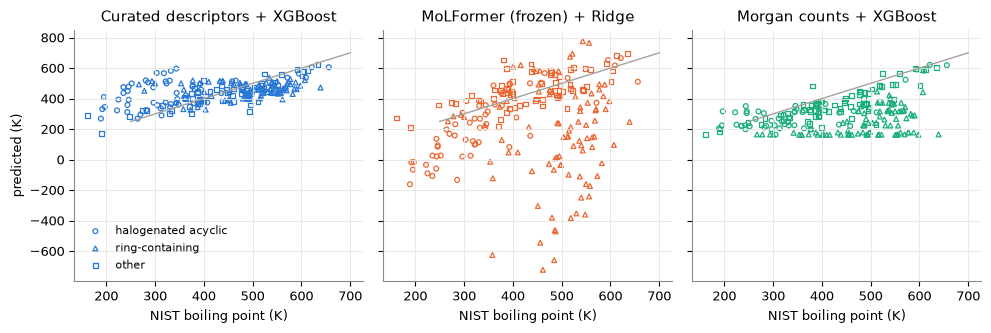

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
subgroup,,,
halogenated acyclic,105.5,146.2,72.3
other,43.9,78.3,72.3
ring-containing,78.3,389.1,254.4
all 211,74.7,224.8,147.4
min prediction (K),171.7,-722.4,161.9


training-mean reference MAE: 94.0 K


,name,subgroup,y_true,y_pred
5183,Iodobenzene,ring-containing,461.6,-722.4
5205,2-Iodotoluene,ring-containing,484.7,-658.6
5181,4-Fluoroiodobenzene,ring-containing,456.2,-544.7
5206,Fluorobenzene,ring-containing,358.0,-625.1
5194,4-Iodotoluene,ring-containing,487.6,-470.1


In [10]:
nb = best[best["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
markers = {"halogenated acyclic": "o", "ring-containing": "^", "other": "s"}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, r in zip(axes, REPS):
    d = nb[nb["representation"] == r]
    for g, m in markers.items():
        s = d[d["subgroup"] == g]
        ax.scatter(s["y_true"], s["y_pred"], s=12, marker=m, facecolors="none", edgecolors=COLORS[r], linewidths=0.9,
                   label=g)
    ax.plot([250, 700], [250, 700], color=GREY, lw=1)
    ax.set(title=f"{NAMES[r]} + {REG[d['regressor'].iloc[0]]}", xlabel="NIST boiling point (K)")
axes[0].set_ylabel("predicted (K)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_nist.png", dpi=150)
plt.show()

table = nb.groupby(["subgroup", "representation"])["abs_err"].mean().unstack()[REPS]
table.loc["all 211"] = nb.groupby("representation")["abs_err"].mean()[REPS]
table.loc["min prediction (K)"] = nb.groupby("representation")["y_pred"].min()[REPS]
mean_ref = refs[(refs["regime"] == "nist") & (refs["reference"] == "training mean")]["abs_err"].mean()
display(table.round(1).rename(columns=NAMES))
print(f"training-mean reference MAE: {mean_ref:.1f} K")
nb[nb["representation"] == "molformer"].nlargest(5, "abs_err").assign(
    name=lambda d: d["key"].map(dict(zip("nist:" + nist.index.astype(str), nist["cmpdname"]))))[
    ["name", "subgroup", "y_true", "y_pred"]].round(1)

- **Only the descriptors beat simply predicting the training mean** (74.7 vs 94.0 K). MoLFormer reaches 224.8 K and Morgan counts 147.4 K.
- MoLFormer's failure is concentrated on ring compounds (389.1 K MAE). It predicts physically impossible negative temperatures, down to −722.4 K for iodobenzene: a linear model extrapolating far outside training data that has no rings or iodine.
- Morgan counts with XGBoost can't extrapolate either: their predictions never go below 161.9 K, and ring compounds pile up near that floor (254.4 K MAE). On halogenated acyclic compounds, though, Morgan counts are best (72.3 K, vs 105.5 K for the descriptors and 146.2 K for MoLFormer).

**Is it the regressor?** The inner cross-validation chose Ridge for MoLFormer everywhere, because it beat XGBoost on familiar chemistry. Trees can't predict outside the range of the training labels, so the controlled XGBoost results (not the best pipeline, shown for comparison) separate the representation from the linear extrapolation:

In [11]:
pn = preds[preds["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
pn.groupby(["subgroup", "representation", "regressor"])["abs_err"].mean().unstack(["representation", "regressor"])[REPS].round(1)

representation      curated         molformer         morgan        
regressor             ridge xgboost     ridge xgboost  ridge xgboost
subgroup                                                            
halogenated acyclic    69.3   105.5     146.2   115.3  114.2    72.3
other                  58.3    43.9      78.3    64.5   71.0    72.3
ring-containing        91.8    78.3     389.1   109.7  108.8   254.4

- **Most of MoLFormer's failure is the linear extrapolation.** With XGBoost, its ring-compound error falls from 389.1 to 109.7 K. It still trails the descriptors' best on rings (78.3 K, XGBoost), and on halogenated acyclic compounds (115.3 vs 69.3 K, descriptors with Ridge).
- The descriptors do better with Ridge than XGBoost on halogenated acyclic compounds (69.3 vs 105.5 K). **A pipeline chosen on familiar data isn't necessarily the best one out of distribution,** a limitation of selecting it by inner cross-validation.
- No combination predicts the NIST compounds well. The best subgroup errors are 43.9–78.3 K, against label noise of about half a kelvin (section 1).

## 7. Fine-tuning MoLFormer: does training the whole encoder help?

A frozen encoder can only offer what pretraining put into its vectors. **Fine-tuning** trains all 44.4 million MoLFormer weights on the boiling points, with a small two-layer network on its pooled output. The design was fixed before any run:
- **Validation:** 15% of each training fold is held out, as whole structure groups and in proportion to the families, and split in half. One half decides when to stop training and which of three learning rates (1e-5, 3e-5, 1e-4) to keep; the other half is untouched until the intervals of section 10.
- **Spelling augmentation:** one molecule can be written as many valid SMILES strings, and section 3 showed the frozen vectors change with the spelling. During training, each molecule gets a new random spelling every epoch.
- **Training:** at most 30 epochs, stopping after 5 epochs without improvement on the stopping half; 3 random seeds per fold at the chosen learning rate. All runs were on a CPU and are exactly reproducible.
- **Inference:** predictions from the canonical SMILES, as for the frozen model. A **spelling-averaged** prediction, the mean over 10 random spellings, is reported alongside.

The fine-tuned MAE is a single run's MAE, averaged over the 3 seeds. The figure pairs each familiar fold's fine-tuned MAE with the frozen best pipeline's (MoLFormer + Ridge) on the same test molecules.

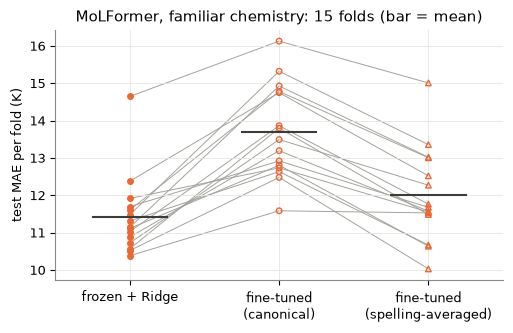

,mean,SD over folds
"frozen MoLFormer + Ridge, full training fold",11.43,1.05
"frozen MoLFormer + Ridge, same 85% as fine-tuning",11.64,1.40
"fine-tuned, canonical",13.70,1.26
"fine-tuned, spelling-averaged",12.01,1.25


In [12]:
ftp = pd.read_csv(f"{FT}/predictions.csv")
ftp["abs_err"] = (ftp["y_pred"] - ftp["y_true"]).abs()
ft_run = ftp.groupby(["regime", "task", "inference", "seed"])["abs_err"].mean()
ft_task = ft_run.groupby(["regime", "task", "inference"]).mean().unstack("inference")   # single-seed MAE, mean over seeds
c5 = pd.read_csv(f"{FT}/c5_folds.csv").set_index("task")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
fam_ft = ft_task.loc["familiar"]
for task in c5.index:
    ys = [c5.loc[task, "frozen_mae"], fam_ft.loc[task, "canonical"], fam_ft.loc[task, "tta"]]
    ax.plot([0, 1, 2], ys, color=GREY, lw=0.7, zorder=1)
ax.scatter(np.zeros(len(c5)), c5["frozen_mae"], s=16, color=COLORS["molformer"], zorder=2)
ax.scatter(np.ones(len(c5)), fam_ft.loc[c5.index, "canonical"], s=16, facecolors="none",
           edgecolors=COLORS["molformer"], linewidths=1, zorder=2)
ax.scatter(np.full(len(c5), 2), fam_ft.loc[c5.index, "tta"], s=16, marker="^", facecolors="none",
           edgecolors=COLORS["molformer"], linewidths=1, zorder=2)
for x, v in enumerate([c5["frozen_mae"], fam_ft["canonical"], fam_ft["tta"]]):
    ax.plot([x - 0.25, x + 0.25], [v.mean()] * 2, color="#3d3c38", lw=1.5)
ax.set_xticks([0, 1, 2], ["frozen + Ridge", "fine-tuned\n(canonical)", "fine-tuned\n(spelling-averaged)"])
ax.set(ylabel="test MAE per fold (K)", xlim=(-0.5, 2.5), title="MoLFormer, familiar chemistry: 15 folds (bar = mean)")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_finetune_folds.png", dpi=150)
plt.show()

matched = pd.read_csv(f"{FT}/frozen_matched_predictions.csv")
matched_fold = (matched["y_pred"] - matched["y_true"]).abs().groupby(matched["task"]).mean()
pd.DataFrame({"mean": [c5["frozen_mae"].mean(), matched_fold.mean(), fam_ft["canonical"].mean(), fam_ft["tta"].mean()],
              "SD over folds": [c5["frozen_mae"].std(), matched_fold.std(), fam_ft["canonical"].std(), fam_ft["tta"].std()]},
             index=["frozen MoLFormer + Ridge, full training fold", "frozen MoLFormer + Ridge, same 85% as fine-tuning",
                    "fine-tuned, canonical", "fine-tuned, spelling-averaged"]).round(2)

- **Fine-tuning makes MoLFormer worse on familiar chemistry:** 13.70 ± 1.26 K against 11.43 ± 1.05 K frozen (+2.27 K). Every one of the 15 lines in the figure rises from frozen to fine-tuned.
- **Holding out 15% for validation is not the cause:** frozen MoLFormer refitted on the same 85% scores 11.64 ± 1.40 K, only 0.21 K above the full training fold (11.43 → 11.64 K).
- **The fine-tuned model still depends on spelling:** averaging over 10 random spellings brings it from 13.70 to 12.01 K, still above the frozen 11.43 K.

**Beyond familiar chemistry.** The same recipe was run on each held-out family, on the NIST set (trained on all 1,250) and on the 250-molecule training subsets of section 8 (one per fold). These runs are descriptive. The frozen columns are each representation's best pipeline in the same setting.

In [13]:
lc_best = pd.read_csv(f"{LC}/best_predictions.csv")
lc_best["abs_err"] = (lc_best["y_pred"] - lc_best["y_true"]).abs()
frozen_task = best.groupby(["regime", "task", "representation"])["abs_err"].mean().unstack()
n250 = lc_best[lc_best["draw"] == 0].query("size == 250").groupby(["fold", "representation"])["abs_err"].mean().unstack()
rows = {}
for label, regime in [("familiar (15 folds)", "familiar"), ("held-out families (mean of 4)", "holdout"), ("NIST (211)", "nist")]:
    rows[label] = {"fine-tuned, canonical": ft_task.loc[regime, "canonical"].mean(),
                   "fine-tuned, spelling-averaged": ft_task.loc[regime, "tta"].mean(),
                   **{f"frozen {NAMES[r].split(' (')[0]}": frozen_task.loc[regime, r].mean() for r in REPS}}
rows["n = 250 (5 folds, draw 0)"] = {"fine-tuned, canonical": ft_task.loc["learning_curve", "canonical"].mean(),
                                     "fine-tuned, spelling-averaged": ft_task.loc["learning_curve", "tta"].mean(),
                                     **{f"frozen {NAMES[r].split(' (')[0]}": n250[r].mean() for r in REPS}}
display(pd.DataFrame(rows).T.round(2))
hold_ft = ft_task.loc["holdout"].join(frozen_task.loc["holdout"])
hold_ft[["canonical", "tta"] + REPS].rename(columns={"canonical": "fine-tuned, canonical", "tta": "fine-tuned, spelling-averaged",
                                                    **NAMES}).round(2)

,"fine-tuned, canonical","fine-tuned, spelling-averaged",frozen Curated descriptors,frozen MoLFormer,frozen Morgan counts
familiar (15 folds),13.70,12.01,11.00,11.43,12.75
held-out families (mean of 4),29.46,27.29,22.51,32.18,30.26
NIST (211),79.05,78.30,74.68,224.81,147.41
"n = 250 (5 folds, draw 0)",22.79,18.94,14.30,13.84,20.61


,"fine-tuned, canonical","fine-tuned, spelling-averaged",Curated descriptors,MoLFormer (frozen),Morgan counts
task,,,,,
alcohol/phenol,60.53,58.20,40.01,58.98,55.77
alkane,11.49,10.62,9.97,9.23,14.35
alkene/alkyne,19.44,15.35,13.31,31.48,27.69
amine,26.39,24.99,26.76,29.03,23.21


- **Held-out families:** fine-tuning beats frozen MoLFormer on average (29.46 vs 32.18 K) but not the curated descriptors (22.51 K). Its gain is concentrated in alkenes/alkynes (31.48 → 19.44 K); alcohols/phenols stay the hardest family (60.53 K fine-tuned, 58.98 frozen, 40.01 curated).
- **NIST:** fine-tuning removes the frozen Ridge readout's runaway extrapolation (224.81 → 79.05 K), coming close to the curated descriptors (74.68 K) without beating them.
- **With 250 training molecules,** fine-tuning is far behind: 22.79 K against 13.84 K for frozen MoLFormer and 14.30 K for curated descriptors on the same subsets.

**Exploratory: why do fine-tuned runs lose?** This was examined after seeing the results, so it is not part of any test. The table lists the familiar folds whose 3 seeds disagree most, and the effect of averaging the 3 seeds' predictions (an ensemble that costs three times the training).

In [14]:
sel = pd.read_csv(f"{FT}/selection.csv")
runs = ft_run.loc["familiar"].xs("canonical", level="inference").rename("test MAE").reset_index()
runs = runs.merge(sel[sel["chosen_lr"]][["task", "seed", "lr", "best_epoch", "epochs_run", "best_stop_mae"]], on=["task", "seed"])
runs["lr"] = runs["lr"].map("{:g}".format)
spread = runs.groupby("task")["test MAE"].agg(["mean", "std", "min", "max"]).sort_values("std", ascending=False)
display(spread.head(4).round(2))
display(runs.nlargest(3, "test MAE").round(2))
fam = ftp[(ftp["regime"] == "familiar")]
ens = fam.groupby(["inference", "task", "key"]).agg(y_true=("y_true", "first"), y_pred=("y_pred", "mean")).reset_index()
ens_fold = (ens["y_pred"] - ens["y_true"]).abs().groupby([ens["inference"], ens["task"]]).mean()
print("3-seed ensemble, fold MAE mean ± SD:",
      {m: f"{ens_fold[m].mean():.2f} ± {ens_fold[m].std():.2f}" for m in ("canonical", "tta")})
print("Spearman, stopping-half MAE vs test MAE over the 45 runs:", round(runs[["best_stop_mae", "test MAE"]].corr("spearman").iloc[0, 1], 2))

,mean,std,min,max
task,,,,
r1f0,13.49,4.45,9.18,18.06
r2f4,15.32,3.99,12.35,19.86
r0f3,14.78,3.83,11.31,18.89
r2f3,13.86,1.64,12.49,15.67


,task,seed,test MAE,lr,best_epoch,epochs_run,best_stop_mae
44,r2f4,2,19.86,1e-05,5,11,17.47
11,r0f3,2,18.89,0.0001,2,8,23.86
17,r1f0,2,18.06,0.0001,1,7,21.42


3-seed ensemble, fold MAE mean ± SD: {'canonical': '11.49 ± 1.25', 'tta': '10.45 ± 1.30'}
Spearman, stopping-half MAE vs test MAE over the 45 runs: 0.42


- **Seeds disagree:** on fold r1f0 the three runs score 9.18 to 18.06 K (SD 4.45). The three worst runs all stopped early, with their best epoch at 1, 2 or 5 and a stopping-half MAE of 17.47 to 23.86 K.
- **The stopping half is a noisy guide:** its MAE ranks the 45 runs' test MAE only moderately (Spearman 0.42).
- **Averaging the 3 seeds' predictions** gives 11.49 ± 1.25 K (canonical) and 10.45 ± 1.30 K (spelling-averaged), level with or below the frozen 11.43 K. This was found after the results and costs three times the training, so it is a lead for further work, not a tested result.

## 8. Learning curves: 100 to ~1,000 training molecules

A pretrained representation might matter most when labels are scarce. Each repeat-0 fold was trained on nested, family-stratified subsets of 100, 250 and 500 molecules, three random draws each, always tested on the full fold. Every choice (regressor, penalty, MoLFormer layer) was made inside the subset. The full-size point is section 4's repeat-0 result (5 folds, one draw), and fine-tuned MoLFormer appears at n = 250 and full size.

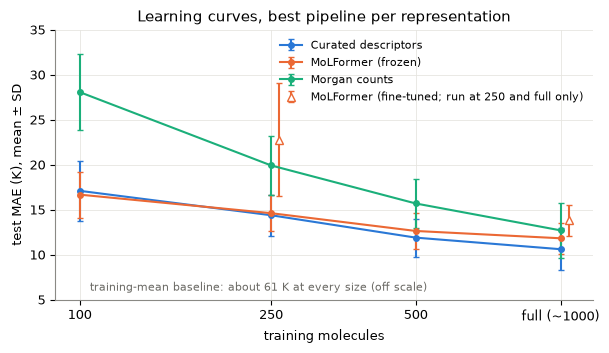

,Curated descriptors,MoLFormer (frozen),Morgan counts,training mean,runs
size,,,,,
100,17.10,16.68,28.07,61.47,15
250,14.39,14.62,19.92,61.06,15
500,11.90,12.64,15.69,60.97,15
full,10.61,11.83,12.71,60.98,5


molformer_minus_curated       morgan_minus_curated      
                        mean   std                 mean   std
size                                                         
100                    -0.42  2.87                10.97  5.01
250                     0.23  1.03                 5.54  2.98
500                     0.74  0.95                 3.79  1.43
full                    1.21  0.88                 2.09  1.02

regressor            ridge  xgboost
size representation                
100  curated            15        0
     molformer          15        0
     morgan              1       14
250  curated             6        9
     molformer          15        0
     morgan              0       15
500  curated             0       15
     molformer          15        0
     morgan              0       15

In [15]:
curves = pd.read_csv(f"{LC}/curves.csv")
curves["size"] = curves["size"].astype(str)
full_n = splits.groupby("fold_r0").size().rsub(len(splits)).mean()                 # ~1,000 training molecules
xpos = {"100": 100, "250": 250, "500": 500, "full": full_n}
bestc = curves[curves["regressor"] == "best"]
stats_ = bestc.groupby(["representation", "size"])["mae"].agg(mean="mean", std="std", runs="count").reset_index()
h5 = pd.read_csv(f"{LC}/h5_finetuned_vs_frozen.csv")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
for r in REPS:
    d = stats_[stats_["representation"] == r].set_index("size").loc[list(xpos)]
    x = [xpos[s] for s in d.index]
    ax.errorbar(x, d["mean"], yerr=d["std"], color=COLORS[r], marker="o", ms=4, capsize=2, lw=1.5, label=NAMES[r])
ft_pts = h5.groupby("size")["finetuned"].agg(["mean", "std"]).loc[["250", "full"]]
ax.errorbar([xpos[s] * 1.04 for s in ft_pts.index], ft_pts["mean"], yerr=ft_pts["std"], color=COLORS["molformer"],
            marker="^", mfc="white", ms=6, capsize=2, ls="none", label="MoLFormer (fine-tuned; run at 250 and full only)")
ref = curves[curves["representation"] == "training mean"].groupby("size")["mae"].mean()
ax.text(105, 6, f"training-mean baseline: about {ref.mean():.0f} K at every size (off scale)", fontsize=8, color="#6b6a65")
ax.set_xscale("log")
ax.set_xticks(list(xpos.values()), ["100", "250", "500", f"full (~{full_n:.0f})"])
ax.minorticks_off()
ax.set(xlabel="training molecules", ylabel="test MAE (K), mean ± SD", ylim=(5, 35),
       title="Learning curves, best pipeline per representation")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_learning_curves.png", dpi=150)
plt.show()

table = stats_.pivot(index="size", columns="representation", values="mean")[REPS].loc[list(xpos)].round(2)
table.columns = [NAMES[c] for c in table.columns]
table["training mean"] = ref.loc[list(xpos)].round(2)
table["runs"] = stats_[stats_["representation"] == "curated"].set_index("size").loc[list(xpos), "runs"].values
display(table)
diffs = pd.read_csv(f"{LC}/differences.csv")
diffs["size"] = diffs["size"].astype(str)
display(diffs.groupby("size")[["molformer_minus_curated", "morgan_minus_curated"]].agg(["mean", "std"]).loc[list(xpos)].round(2))
chosen = pd.read_csv(f"{LC}/best_selection.csv")
chosen["size"] = chosen["task"].str.extract(r"n(\d+)_")[0]
chosen.groupby(["size", "representation"])["regressor"].value_counts().unstack().fillna(0).astype(int)

- **Curated descriptors and frozen MoLFormer track each other at every size:** 17.10 vs 16.68 K at n = 100, 10.61 vs 11.83 K at full size. MoLFormer − curated moves from −0.42 ± 2.87 K (n = 100) through +0.23 ± 1.03 and +0.74 ± 0.95 to +1.21 ± 0.88 K (full): if anything, the pretrained representation's relative standing falls as data grows.
- **Morgan counts need the most data:** 28.07 K at n = 100, falling to 12.71 K at full size; their gap to the curated descriptors shrinks from 10.97 to 2.09 K.
- **Regressor choice shifts with size for the descriptors only:** curated descriptors take Ridge at n = 100 (15/15) and XGBoost at n = 500 (15/15); MoLFormer takes Ridge at every size (15/15); Morgan counts take XGBoost in 44 of 45 runs.
- Every curve sits far below the training-mean baseline (60.97–61.47 K).

**Fine-tuning at n = 250.** The fine-tuned model trains on about 212 of the 250 molecules (the rest validate), so it is compared both with the frozen best pipeline on all 250 and with frozen MoLFormer + Ridge refitted on the same ~212 ("matched"). Positive means fine-tuning is worse.

In [16]:
h5.groupby("size")[["finetuned", "frozen_best", "frozen_matched", "minus_best", "minus_matched"]].agg(["mean", "std"]).round(2)

finetuned       frozen_best       frozen_matched       minus_best        \
          mean   std        mean   std           mean   std       mean   std   
size                                                                           
250      22.79  6.26       13.84  2.10          14.82  2.09       8.95  4.35   
full     13.81  1.76       11.83  1.71          11.17  2.19       1.98  1.14   

     minus_matched        
              mean   std  
size                      
250           7.97  4.26  
full          2.64  1.35

- **With 250 molecules, fine-tuning trails frozen MoLFormer by 8.95 ± 4.35 K** (22.79 vs 13.84 K), and by 7.97 ± 4.26 K against frozen MoLFormer on the same ~212 molecules (14.82 K).
- At full size on the same repeat-0 folds the gaps are +1.98 ± 1.14 and +2.64 ± 1.35 K. **The gap widens with less data, instead of narrowing as H5 expected.**

## 9. Confirmatory comparisons C1–C5, and descriptive Morgan contrasts

These are the five tests fixed before any result. C1–C4 are MAE(frozen MoLFormer) − MAE(curated descriptors), C5 is MAE(fine-tuned) − MAE(frozen MoLFormer); positive means the first is worse.
- **C1, C4, C5** use the corrected resampled t-test of Nadeau & Bengio (2003, *Machine Learning* 52). Repeated cross-validation runs share training data, so it widens the plain t-test's variance by (1/J + n_test/n_train) over J runs. For C4 (n_train ≈ 100, n_test ≈ 250) that factor is large, so C4 can only detect large differences; the **minimum detectable difference** is the standard error (SE) × the two-sided 5% t critical value.
- **C2 and C3** average the per-family or per-subgroup differences with equal weight; their 95% confidence intervals (CI) come from 10,000 bootstrap resamples of molecules within each family or subgroup. None of the resamples crossed zero, so p < 2/10,000; Holm's correction uses that bound.
- **Holm's correction** (Holm, 1979, *Scandinavian Journal of Statistics* 6) is applied across all five at α = 0.05. A **finding** needs a Holm-adjusted p < 0.05 *and* a difference of at least 1.0 K.

In [17]:
conf = pd.read_csv(f"{R}/confirmatory.csv")
c4 = pd.read_csv(f"{LC}/c4_provisional.csv")
boot = conf["test"] == "bootstrap"
conf["p (raw)"] = [("< 0.0002" if b and p == 0 else f"{p:.3f}") for p, b in zip(conf["p_raw"], boot)]
conf["p (Holm)"] = [(f"≤ {p:.3f}" if b else f"{p:.3f}") for p, b in zip(conf["p_holm"], boot)]
conf["min. detectable (K)"] = conf["comparison"].map({"C4": round(float(c4["min_detectable"].iloc[0]), 2)})
show = conf.set_index("comparison")[["hypothesis", "contrast", "estimate", "se", "ci_low", "ci_high", "p (raw)", "p (Holm)",
                                     "min. detectable (K)", "finding"]]
show.round(2)

,hypothesis,contrast,estimate,se,ci_low,ci_high,p (raw),p (Holm),min. detectable (K),finding
comparison,,,,,,,,,,
C1,H1,"frozen MoLFormer - curated (log), familiar, 15 folds",0.43,0.63,NaN,NaN,0.506,1.000,NaN,False
C2,H2,"frozen MoLFormer - curated (log), held-out families, macro-average of 4",9.67,NaN,8.40,10.95,< 0.0002,≤ 0.001,NaN,True
C3,H3,"frozen MoLFormer - curated (log), NIST external, macro-average of 3 subgroups",128.69,NaN,105.96,152.70,< 0.0002,≤ 0.001,NaN,True
C4,H4,"frozen MoLFormer - curated (log), familiar, n = 100, 5 folds x 3 draws",-0.42,4.59,NaN,NaN,0.928,1.000,9.85,False
C5,H5,"fine-tuned - frozen MoLFormer, familiar, 15 folds",2.27,0.55,NaN,NaN,0.001,0.003,NaN,True


- **Three findings, all against the language model:** frozen MoLFormer is worse than the curated descriptors on unseen families (C2, +9.67 K, 95% CI 8.40 to 10.95) and on the NIST set (C3, +128.69 K, 95% CI 105.96 to 152.70), and fine-tuning is worse than freezing (C5, +2.27 K, SE 0.55, Holm p = 0.003).
- **No difference was detected on familiar chemistry** (C1, +0.43 K, Holm p = 1.000), nor with 100 training molecules (C4, −0.42 K, Holm p = 1.000). C4 could only have detected a difference of 9.85 K or more, so it means "not detectable", not "no difference".
- **By hypothesis:** H1 (curated ≥ CLM on familiar chemistry) holds only as a tie; H2 and H3 resolve against the CLM; H4 (a CLM advantage at n = 100) finds no support at this power; H5 (fine-tuning beats frozen) is contradicted.

**Descriptive: where Morgan counts sit.** The three representations run from expert-designed to learned. The curated descriptors are global physical properties a chemist chose for boiling (size, polarity, hydrogen bonding). Morgan counts are a fixed rule with no chemistry knowledge and no training: how often each local atom environment (up to two bonds out) occurs. MoLFormer's vectors are learned from unlabelled SMILES. Two contrasts place Morgan between the other two:
- **Morgan − curated:** is a generic list of substructures enough, or does encoding the physics matter?
- **Morgan − frozen MoLFormer:** does pretraining add anything beyond counting substructures?

Morgan counts were pre-registered as a descriptive baseline, so these rows are not part of the confirmatory family. They use the same best pipelines, settings and tests as C1–C4 (`scripts/morgan_descriptive.py` recomputes C1–C4 through the same code as a check), but they get raw p-values only: no Holm correction and no "finding". Positive means Morgan is worse.

In [18]:
mdesc = pd.read_csv(f"{R}/morgan_descriptive.csv")
mboot = mdesc["test"] == "bootstrap"
mdesc["p (raw)"] = [("< 0.0002" if b and p == 0 else f"{p:.3f}") for p, b in zip(mdesc["p_raw"], mboot)]
mdesc = mdesc.rename(columns={"as_in": "setting as in", "min_detectable": "min. detectable (K)"})
mdesc.set_index(["contrast", "setting as in"])[["setting", "estimate", "se", "ci_low", "ci_high", "p (raw)",
                                                "min. detectable (K)"]].round(2)

setting  \
contrast                  setting as in                                                
Morgan - curated (log)    C1                                      familiar, 15 folds   
                          C2                   held-out families, macro-average of 4   
                          C3             NIST external, macro-average of 3 subgroups   
                          C4                    familiar, n = 100, 5 folds x 3 draws   
Morgan - frozen MoLFormer C1                                      familiar, 15 folds   
                          C2                   held-out families, macro-average of 4   
                          C3             NIST external, macro-average of 3 subgroups   
                          C4                    familiar, n = 100, 5 folds x 3 draws   

                                         estimate    se  ci_low  ci_high  \
contrast                  setting as in                                    
Morgan - curated (log)    C1                 1.75  0.53     NaN      NaN   
                          C2                 7.74   NaN    6.33     9.18   
                          C3                57.17   NaN   45.44    68.57   
                          C4                10.97  8.02     NaN      NaN   
Morgan - frozen MoLFormer C1                 1.32  0.61     NaN      NaN   
                          C2                -1.92   NaN   -3.49    -0.34   
                          C3               -71.53   NaN  -96.49   -47.28   
                          C4                11.39  6.69     NaN      NaN   

                                          p (raw)  min. detectable (K)  
contrast                  setting as in                                 
Morgan - curated (log)    C1                0.005                  NaN  
                          C2             < 0.0002                  NaN  
                          C3             < 0.0002                  NaN  
                          C4                0.193                17.20  
Morgan - frozen MoLFormer C1                0.048                  NaN  
                          C2                0.020                  NaN  
                          C3             < 0.0002                  NaN  
                          C4                0.111                14.35

The held-out and NIST rows are equal-weight averages over families or subgroups. Each family's or subgroup's own difference (K):

In [19]:
strata = pd.DataFrame({(c, a): json.loads(s) for c, a, s in zip(mdesc["contrast"], mdesc["setting as in"],
                                                                 mdesc["per_stratum"]) if isinstance(s, str)})
strata.round(2).astype(object).where(strata.notna(), "")

Morgan - curated (log)         Morgan - frozen MoLFormer  \
                                        C2      C3                        C2   
alcohol/phenol                       15.76                             -3.21   
alkane                                4.38                              5.13   
alkene/alkyne                        14.39                             -3.78   
amine                                -3.55                             -5.82   
halogenated acyclic                         -33.13                             
other                                        28.48                             
ring-containing                             176.15                             

                             
                         C3  
alcohol/phenol               
alkane                       
alkene/alkyne                
amine                        
halogenated acyclic  -73.91  
other                 -5.93  
ring-containing     -134.73

- **Morgan − curated: Morgan is worse in every setting.** It trails by +1.75 K on familiar chemistry (SE 0.53, p 0.005), +7.74 K on held-out families (95% CI 6.33 to 9.18) and +57.17 K on NIST (95% CI 45.44 to 68.57). At n = 100 the gap is +10.97 K, but with SE 8.02 (p 0.193) it is below the 17.20 K this design could detect. Counting substructures does not replace descriptors that encode size, polarity and hydrogen bonding.
- **Morgan − frozen MoLFormer: the sign depends on the regime.** Pretraining helps where test chemistry resembles training: Morgan is +1.32 K worse on familiar chemistry (p 0.048) and +11.39 K worse at n = 100 (p 0.111, below the 14.35 K detectable). Under shift, Morgan is better: −1.92 K on held-out families (95% CI −3.49 to −0.34) and −71.53 K on NIST (95% CI −96.49 to −47.28).
- **By family and subgroup,** Morgan beats curated only on amines (−3.55 K) and halogenated acyclic NIST compounds (−33.13 K); its NIST deficit comes from ring-containing compounds (+176.15 K). It beats MoLFormer in every NIST subgroup (−5.93 to −134.73 K) and in three of the four held-out families, all but alkanes (+5.13 K).
- **These are raw p-values over eight descriptive contrasts, with no multiplicity correction.** The familiar-chemistry Morgan − MoLFormer gap (p 0.048) is borderline.

## 10. Prediction intervals and uncertainty: are the error bars honest?

A model used to choose which compounds to measure needs error bars that hold. Each method gets a 90% **prediction interval** per test molecule; its **coverage** is the share of test molecules whose measured value falls inside. Both methods are conformal: distribution-free, and guaranteed only when test molecules are exchangeable with the training data, which the family holdout and the NIST set deliberately are not.
- **Frozen models: CV+ (cross-validation plus;** Barber, Candès, Ramdas & Tibshirani 2021, *Annals of Statistics* 49). The three inner-fold models' predictions, each widened by every training molecule's error under the model that didn't see it. In the holdout regime the inner folds are whole families, so these intervals are calibrated across families (a heuristic: the guarantee needs equal-sized random folds).
- **Fine-tuned model: split conformal** (Lei, G'Sell, Rinaldo, Tibshirani & Wasserman 2018, *JASA* 113). The 3-seed mean prediction ± the 90th-percentile error on the untouched calibration half (~75 molecules; drawn from the training families).
- **Mondrian CV+** (Vovk, Gammerman & Shafer 2005) calibrates each family on its own errors, in the familiar regime.

The CV+ inner models train on ~2/3 of the fold and the fine-tuned model on ~85%, so widths compare methods *and* training sizes; they are only comparable where coverage is near 90%.

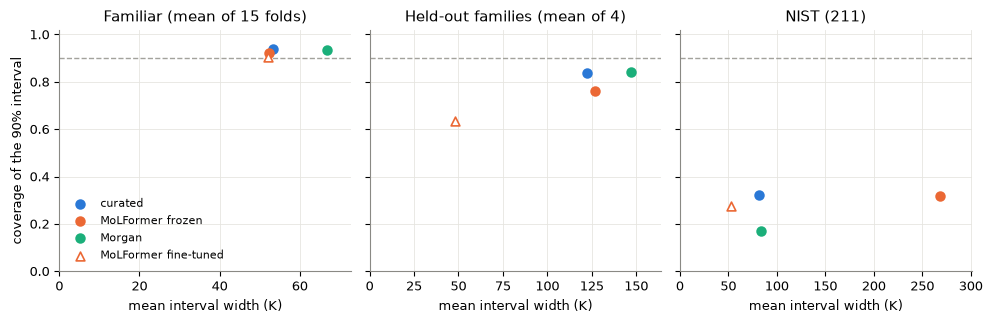

coverage  coverage_sd    width
regime   method                                              
familiar curated                  0.940        0.017   53.187
         MoLFormer fine-tuned     0.905        0.053   52.078
         MoLFormer frozen         0.921        0.017   52.345
         Morgan                   0.936        0.020   66.690
holdout  curated                  0.835        0.269  122.336
         MoLFormer fine-tuned     0.634        0.386   48.162
         MoLFormer frozen         0.761        0.361  126.511
         Morgan                   0.839        0.255  147.075
nist     curated                  0.322          NaN   82.060
         MoLFormer fine-tuned     0.275          NaN   52.300
         MoLFormer frozen         0.318          NaN  267.960
         Morgan                   0.171          NaN   83.225

curated  MoLFormer fine-tuned  MoLFormer frozen  \
regime  group                                                                  
holdout alcohol/phenol         0.436                 0.088             0.225   
        alkane                 0.997                 0.820             0.995   
        alkene/alkyne          0.992                 0.973             0.951   
        amine                  0.915                 0.655             0.873   
nist    all                    0.322                 0.275             0.318   
        halogenated acyclic    0.211                 0.193             0.439   
        other                  0.463                 0.463             0.149   
        ring-containing        0.287                 0.184             0.368   

                             Morgan    n  
regime  group                             
holdout alcohol/phenol        0.459  351  
        alkane                0.990  388  
        alkene/alkyne         0.973  366  
        amine                 0.937  142  
nist    all                   0.171  211  
        halogenated acyclic   0.316   57  
        other                 0.269   67  
        ring-containing       0.000   87

In [20]:
cov = pd.read_csv(f"{U}/coverage.csv")
METHODS = {"curated_frozen": ("curated", "o", COLORS["curated"], "full"),
           "molformer_frozen": ("MoLFormer frozen", "o", COLORS["molformer"], "full"),
           "morgan_frozen": ("Morgan", "o", COLORS["morgan"], "full"),
           "molformer_finetuned_ensemble": ("MoLFormer fine-tuned", "^", COLORS["molformer"], "none")}
primary = cov[(cov["group"] == "all") & cov["variant"].isin(["cvplus", "split"]) & cov["method"].isin(METHODS)]
summ = primary.groupby(["regime", "method"])[["coverage", "width"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, (regime, title) in zip(axes, [("familiar", "Familiar (mean of 15 folds)"), ("holdout", "Held-out families (mean of 4)"),
                                      ("nist", "NIST (211)")]):
    for m, (label, marker, color, fill) in METHODS.items():
        c, w = summ.loc[(regime, m)]
        ax.scatter(w, c, s=40, marker=marker, color=color, facecolors=color if fill == "full" else "white",
                   linewidths=1.2, label=label, zorder=3)
    ax.axhline(0.9, color=GREY, ls="--", lw=1)
    ax.set(title=title, xlabel="mean interval width (K)")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.08)
axes[0].set(ylabel="coverage of the 90% interval", ylim=(0, 1.02))
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_interval_coverage.png", dpi=150)
plt.show()

wide = primary.groupby(["regime", "method"]).agg(coverage=("coverage", "mean"), coverage_sd=("coverage", "std"),
                                                 width=("width", "mean")).round(3)
display(wide.rename(index={m: v[0] for m, v in METHODS.items()}))
per = cov[(cov["regime"] != "familiar") & cov["variant"].isin(["cvplus", "split"]) & cov["method"].isin(METHODS)]
per = per[((per["regime"] == "holdout") & (per["group"] == "all")) | (per["regime"] == "nist")]
per = per.assign(group=np.where(per["regime"] == "holdout", per["task"], per["group"]))   # holdout: one family per task
per.pivot_table(index=["regime", "group"], columns="method", values="coverage").rename(
    columns={m: v[0] for m, v in METHODS.items()}).round(3).join(
    per.groupby(["regime", "group"])["n"].first())

- **Familiar chemistry:** every method reaches the 90% target. CV+ gives 0.921–0.940; the fine-tuned split-conformal intervals give 0.905 but vary about three times more between folds (SD 0.053 vs 0.017–0.020), because they rest on ~75 calibration molecules.
- **Held-out families:** all fall short. Curated 0.835 and Morgan 0.839 come closest, at widths of 122 and 147 K; the fine-tuned intervals are narrow (48 K) and cover only 0.634. Alcohols/phenols are under-covered by every method (0.088–0.459).
- **NIST:** coverage collapses to 0.171–0.322. Frozen MoLFormer covers only 0.318 despite a 268 K mean width, because its intervals are centred on wrong predictions; Morgan covers none of the 87 ring compounds (0.000).

**One width per model hides the families.** Familiar-chemistry errors differ by family, so a single interval width is too wide for some and too narrow for others. Left: one width per model (CV+, and split conformal for the fine-tuned model). Right: Mondrian CV+, calibrated per family. The family "other" has about one test molecule per fold and is left out.

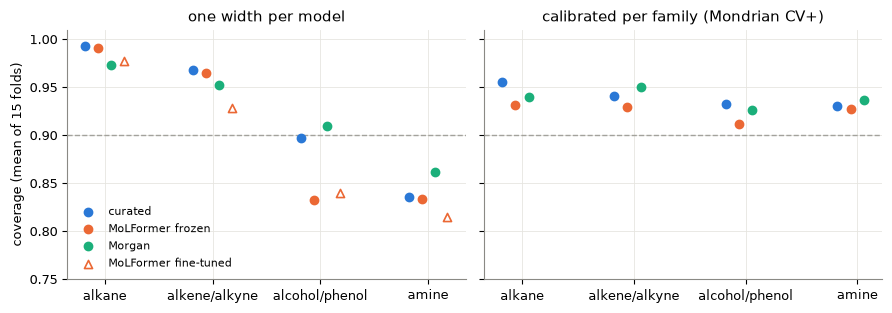

coverage                       \
group                                 alcohol/phenol alkane alkene/alkyne   
method               variant                                                
curated              cvplus                    0.897  0.993         0.968   
                     cvplus_mondrian           0.933  0.955         0.941   
MoLFormer fine-tuned split                     0.840  0.978         0.929   
                     split_normalised          0.835  0.969         0.900   
MoLFormer frozen     cvplus                    0.833  0.991         0.964   
                     cvplus_mondrian           0.912  0.932         0.930   
Morgan               cvplus                    0.910  0.973         0.953   
                     cvplus_mondrian           0.926  0.940         0.950   

                                                      width          \
group                                  amine alcohol/phenol  alkane   
method               variant                                          
curated              cvplus            0.836         55.712  50.204   
                     cvplus_mondrian   0.930         78.810  25.429   
MoLFormer fine-tuned split             0.815         52.078  52.078   
                     split_normalised  0.810         51.020  42.262   
MoLFormer frozen     cvplus            0.834         53.482  49.773   
                     cvplus_mondrian   0.928         85.206  26.913   
Morgan               cvplus            0.862         67.773  63.453   
                     cvplus_mondrian   0.937         79.061  41.443   

                                                              
group                                 alkene/alkyne    amine  
method               variant                                  
curated              cvplus                  51.357   59.719  
                     cvplus_mondrian         38.147  137.835  
MoLFormer fine-tuned split                   52.078   52.078  
                     split_normalised        49.417   56.023  
MoLFormer frozen     cvplus                  51.744   57.816  
                     cvplus_mondrian         37.112  111.028  
Morgan               cvplus                  66.903   72.194  
                     cvplus_mondrian         64.639  134.096

test molecules per fold: {'alcohol/phenol': 70.2, 'alkane': 77.6, 'alkene/alkyne': 73.2, 'amine': 28.4}


In [21]:
fc = cov[(cov["regime"] == "familiar") & ~cov["group"].isin(["all", "other"])]
FAMS = ["alkane", "alkene/alkyne", "alcohol/phenol", "amine"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
panels = [("one width per model", {"curated_frozen": "cvplus", "molformer_frozen": "cvplus", "morgan_frozen": "cvplus",
                                   "molformer_finetuned_ensemble": "split"}),
          ("calibrated per family (Mondrian CV+)", {"curated_frozen": "cvplus_mondrian", "molformer_frozen": "cvplus_mondrian",
                                                   "morgan_frozen": "cvplus_mondrian"})]
for ax, (title, which) in zip(axes, panels):
    for k, (m, variant) in enumerate(which.items()):
        label, marker, color, fill = METHODS[m]
        d = fc[(fc["method"] == m) & (fc["variant"] == variant)].groupby("group")["coverage"].mean().loc[FAMS]
        ax.scatter(np.arange(4) + (k - 1.5) * 0.12, d, marker=marker, s=34, color=color,
                   facecolors=color if fill == "full" else "white", linewidths=1.2, label=label, zorder=3)
    ax.axhline(0.9, color=GREY, ls="--", lw=1)
    ax.set_xticks(range(4), FAMS)
    ax.set(title=title, ylim=(0.75, 1.01))
axes[0].set_ylabel("coverage (mean of 15 folds)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_coverage_by_family.png", dpi=150)
plt.show()
fam_tab = fc[fc["method"].isin(METHODS)].groupby(["method", "variant", "group"])[["coverage", "width"]].mean().unstack("group")
display(fam_tab.round(3).rename(index={m: v[0] for m, v in METHODS.items()}))
print("test molecules per fold:", fc.groupby("group")["n"].mean().round(1).to_dict())

- **One width per model over-covers alkanes and under-covers amines:** alkanes 0.973–0.993, amines 0.815–0.862 across the four methods.
- **Per-family calibration fixes it** for the frozen models (every family 0.912–0.955), by making the intervals honest rather than uniform: amine widths grow from 58–72 K to 111–138 K, alkane widths shrink from 50–63 K to 25–41 K.
- A model used to rank candidates should therefore report family-calibrated intervals; the fine-tuned model's calibration half is too small to split this way.

**Does a model know which of its predictions are bad?** Each method's per-molecule uncertainty is the disagreement of its three inner models (frozen) or three seeds (fine-tuned). A model-free baseline is the **distance to the training set**: 1 − the highest Tanimoto similarity of the molecule's Morgan counts to any training molecule. The table gives the Spearman rank correlation of each score with the absolute error (familiar: mean over folds). The figure shows what the ranking is worth in familiar chemistry: the MAE of the x% most confident predictions, against random order and the oracle that sorts by the true error.

score                          distance  model
regime   method                               
familiar curated                   0.13   0.43
         MoLFormer fine-tuned      0.10   0.27
         MoLFormer frozen          0.21   0.35
         Morgan                    0.27   0.38
holdout  curated                   0.02   0.19
         MoLFormer fine-tuned      0.17   0.17
         MoLFormer frozen          0.15   0.28
         Morgan                    0.31   0.14
nist     curated                   0.46   0.26
         MoLFormer fine-tuned      0.42   0.32
         MoLFormer frozen          0.44   0.54
         Morgan                    0.71   0.37

familiar, mean within-family Spearman:


score,distance,model
method,,
curated,0.03,0.34
MoLFormer frozen,0.11,0.26
Morgan,0.18,0.33
MoLFormer fine-tuned,0.05,0.19


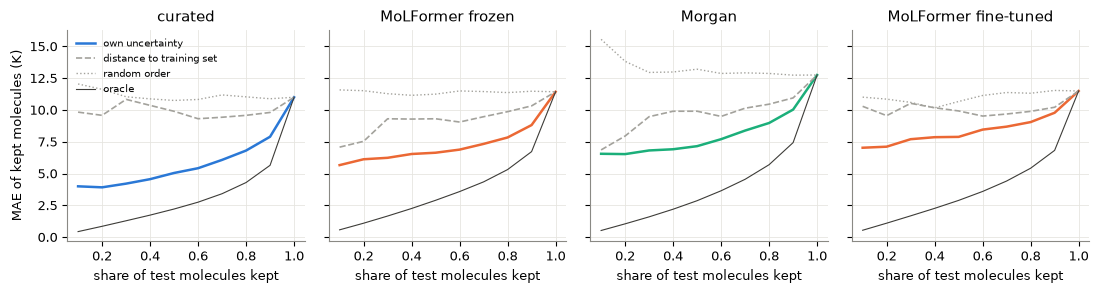

fraction                                 0.1    0.2    0.5    1.0
method                       score                               
curated_frozen               distance   9.83   9.58   9.89  11.00
                             model      3.99   3.91   5.04  11.00
                             oracle     0.43   0.85   2.21  11.00
                             random    12.04  11.62  10.75  11.00
molformer_frozen             distance   7.08   7.53   9.31  11.43
                             model      5.66   6.12   6.64  11.43
                             oracle     0.57   1.09   2.90  11.43
                             random    11.57  11.51  11.24  11.43
morgan_frozen                distance   6.86   7.95   9.90  12.75
                             model      6.55   6.53   7.15  12.75
                             oracle     0.52   1.04   2.86  12.75
                             random    15.55  13.82  13.20  12.75
molformer_finetuned_ensemble distance  10.28   9.55   9.92  11.49
                             model      7.03   7.11   7.88  11.49
                             oracle     0.54   1.10   2.89  11.49
                             random    11.01  10.85  10.66  11.49

In [22]:
sp = pd.read_csv(f"{U}/spearman.csv")
pooled = sp[sp["scope"] == "all"].groupby(["regime", "method", "score"])["spearman"].mean().unstack("score")
within = sp[(sp["regime"] == "familiar") & (sp["scope"] != "all")].groupby(["method", "score"])["spearman"].mean().unstack()
pooled = pooled.loc[[i for i in pooled.index if i[1] != "molformer_finetuned_seed0"]]
display(pooled.rename(index={m: v[0] for m, v in METHODS.items()}).round(2))
print("familiar, mean within-family Spearman:")
display(within.loc[list(METHODS)].rename(index={m: v[0] for m, v in METHODS.items()}).round(2))

ret = pd.read_csv(f"{U}/retention.csv").groupby(["method", "score", "fraction"])["mae"].mean()
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for ax, (m, (label, marker, color, fill)) in zip(axes, METHODS.items()):
    r = ret.loc[m]
    ax.plot(r.loc["model"].index, r.loc["model"], color=color, lw=1.8, label="own uncertainty")
    ax.plot(r.loc["distance"].index, r.loc["distance"], color=GREY, lw=1.2, ls="--", label="distance to training set")
    ax.plot(r.loc["random"].index, r.loc["random"], color=GREY, lw=1, ls=":", label="random order")
    ax.plot(r.loc["oracle"].index, r.loc["oracle"], color="#3d3c38", lw=0.8, label="oracle")
    ax.set(title=label, xlabel="share of test molecules kept")
axes[0].set_ylabel("MAE of kept molecules (K)")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_retention.png", dpi=150)
plt.show()
ret.unstack("fraction")[[0.1, 0.2, 0.5, 1.0]].loc[list(METHODS)].round(2)

- **In familiar chemistry, each model's own uncertainty ranks its errors better than distance to the training set:** Spearman 0.27–0.43 against 0.10–0.27 pooled, and 0.19–0.34 against 0.03–0.18 within families. The fine-tuned seed spread is the weakest model score (0.27).
- **That ranking is useful:** keeping the curated model's most confident 50% of molecules lowers MAE from 11.00 to 5.04 K (the oracle reaches 2.21 K); for frozen MoLFormer 11.43 → 6.64 K, Morgan 12.75 → 7.15 K, fine-tuned 11.49 → 7.88 K.
- **Under shift the picture changes:** on NIST, distance to the training set ranks errors as well as or better than the models' own uncertainty for three of four methods (Morgan 0.71 vs 0.37, curated 0.46 vs 0.26, fine-tuned 0.42 vs 0.32; frozen MoLFormer 0.44 vs 0.54). On held-out families every score is weak (0.02–0.31).

## 11. Key findings

1. **Familiar chemistry: a pretrained language model matches but does not beat physically motivated descriptors.** Frozen MoLFormer scores 11.43 K against 11.00 K for curated descriptors (C1: +0.43 K, not a finding), and the two track each other down to 100 training molecules (17.10 vs 16.68 K; C4: −0.42 K, detectable only above 9.85 K).
2. **Unfamiliar chemistry: frozen embeddings generalise worse.** MoLFormer is +9.67 K on unseen families and +128.69 K on the NIST set (C2, C3). A linear readout of frozen embeddings extrapolates without bound, down to −722.4 K for iodobenzene (section 6).
3. **Fine-tuning does not rescue it.** Fine-tuned MoLFormer is worse than frozen on familiar chemistry (C5: +2.27 K, all 15 folds) and much worse with 250 molecules (+8.95 K). It does remove the NIST blow-up (79.05 K), without beating the descriptors (74.68 K). Runs are unstable across seeds; a 3-seed ensemble (11.49 K, exploratory) is the only variant level with the frozen model.
4. **Error bars hold only for familiar chemistry.** Conformal intervals reach 90% coverage there (0.905–0.940), but need per-family calibration to be honest for each family, and fail under shift: 0.634–0.839 on held-out families, 0.171–0.322 on NIST. The models' own uncertainty ranks errors well in familiar chemistry (keeping the curated model's most confident half: 11.00 → 5.04 K); for novel chemistry, distance to the training set is the more reliable warning.
5. **What the embeddings carry:** the useful signal sits in an early layer (layer 1: 11.21 K; pooled output: 17.80 K), and the embeddings depend strongly on how a SMILES string is written (retrieval share ≤ 0.201).
6. **Substructure counts (Morgan, descriptive baseline) sit between the two.** They never beat the curated descriptors on average (+1.75 K familiar, +7.74 K held-out families, +57.17 K NIST), but they hold up better than MoLFormer under shift (−1.92 K held-out families, −71.53 K NIST). MoLFormer is ahead of plain substructure counts only on familiar chemistry (Morgan +1.32 K, p 0.048, uncorrected), so what pretraining adds does not transfer to new chemistry (section 9).

**In practice,** for boiling points of small organic molecules, curated descriptors with XGBoost remain the better choice: as accurate on familiar chemistry and far more robust outside it. A pretrained chemical language model earns its place only with evidence it beats them on the target chemistry, and any model used on new chemistry should report family-calibrated intervals and flag molecules far from the training set.